# Giai đoạn 3: Phân tích dữ liệu bằng Python
**Dự án:** Phân tích dữ liệu thương mại điện tử Olist (Brazil, 2016–2018)

Notebook này tiếp nối `03_analysis_SQL.ipynb`, sử dụng cùng view `v_review_order_features` và cùng đơn vị phân tích: một đơn hàng đã giao có review. Tám câu dưới đây được đánh số lại từ **Câu 1 đến Câu 8**, tương ứng với Q03–Q10 trong notebook SQL. Cách tổng hợp ở cấp đơn hàng giúp tránh đếm lặp sản phẩm, thanh toán hoặc người bán.

**Câu hỏi phân tích:**
1. Doanh thu tăng trưởng thế nào theo thời gian? Khách mua vào lúc nào?
2. Danh mục nào đóng góp doanh thu chính?
3. Khách hàng tập trung ở đâu, vùng nào giao hàng chậm?
4. Giao hàng trễ ảnh hưởng thế nào đến đánh giá của khách? (kiểm định thống kê)
5. Khách thanh toán bằng phương thức nào, trả góp ra sao?
6. Khách hàng có quay lại mua không?

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


def find_project_root(start_dir: Path) -> Path:
    for candidate in (start_dir, *start_dir.parents):
        if (
            (candidate / "data" / "olist.db").is_file()
            and (candidate / "sql" / "03_queries.sql").is_file()
            and (candidate / "Notebooks").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        f"Không tìm thấy thư mục gốc dự án từ {start_dir}. "
        "Hãy chạy scripts/database/build_db.py trước để tạo data/olist.db."
    )


BASE_DIR = find_project_root(Path.cwd().resolve())
DB_PATH = BASE_DIR / "data" / "olist.db"
FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(filename: str) -> None:
    plt.gcf().savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")


def format_p_value(p_value: float) -> str:
    return "<0.001" if p_value < 0.001 else f"{p_value:.3g}"

with sqlite3.connect(DB_PATH) as conn:
    available_views = {
        row[0]
        for row in conn.execute(
            "SELECT name FROM sqlite_master WHERE type = 'view'"
        )
    }
    if "v_review_order_features" not in available_views:
        raise RuntimeError(
            "Database chưa có view v_review_order_features. "
            "Hãy chạy scripts/database/build_db.py để dựng lại database."
        )
    review_orders = pd.read_sql_query(
        "SELECT * FROM v_review_order_features ORDER BY purchase_year_month, order_id",
        conn,
    )

review_orders["is_late"] = review_orders["is_late"].astype(bool)
review_orders["review_score"] = review_orders["review_score"].astype(int)
review_orders["low_score"] = review_orders["review_score"] <= 2
review_orders["positive_review"] = review_orders["review_score"] >= 4
review_orders["purchase_year_month"] = pd.to_datetime(
    review_orders["purchase_year_month"], format="%Y-%m"
)
ALPHA = 0.05
print(f"Database: {DB_PATH}")
print(f"Đơn hàng có review trong view SQL: {len(review_orders):,}")
print("Thang điểm review:", sorted(review_orders["review_score"].unique()))


Database: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\data\olist.db
Đơn hàng có review trong view SQL: 95,329
Thang điểm review: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## Câu 1 — Phân bố và mất cân bằng review score

Đếm số đơn và tỷ lệ của từng mức 1–5 sao. Phân bố này giúp giải thích vì sao các phân tích/mô hình sau cần xem xét tỷ lệ lớp thay vì chỉ dựa vào accuracy.


In [2]:
q03 = (
    review_orders.groupby("review_score")
    .agg(order_count=("order_id", "size"))
    .reindex(range(1, 6), fill_value=0)
)
q03["percentage"] = (q03["order_count"] / q03["order_count"].sum() * 100).round(2)
print(f"Điểm review trung bình toàn bộ: {review_orders['review_score'].mean():.2f}")
display(q03)

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.2f}'.format)
PRO_DIR = '../data/processed/'

master = pd.read_csv(os.path.join(PRO_DIR, 'olist_master.csv'),
                     dtype={'customer_zip_code_prefix': str, 'seller_zip_code_prefix': str},
                     parse_dates=['order_purchase_timestamp'])

# Bảng mức đơn hàng để không đếm lặp payment/review khi đơn có nhiều sản phẩm
orders = (master.groupby('order_id', as_index=False)
          .agg(customer_unique_id=('customer_unique_id', 'first'),
               customer_state=('customer_state', 'first'),
               customer_zip_code_prefix=('customer_zip_code_prefix', 'first'),
               purchase_ts=('order_purchase_timestamp', 'first'),
               year_month=('purchase_year_month', 'first'),
               weekday=('purchase_weekday', 'first'),
               hour=('purchase_hour', 'first'),
               n_items=('order_item_id', 'count'),
               product_value=('price', 'sum'),
               freight_value=('freight_value', 'sum'),
               payment_total=('payment_total', 'first'),
               payment_type=('payment_type', 'first'),
               payment_installments=('payment_installments', 'first'),
               delivery_days=('delivery_days', 'first'),
               estimated_days=('estimated_days', 'first'),
               delay_days=('delay_days', 'first'),
               is_late=('is_late', 'first'),
               review_score=('review_score', 'first'),
               same_state=('same_state', 'all')))
print(f'master: {master.shape[0]:,} dòng | orders: {orders.shape[0]:,} đơn')

orders.head()

Điểm review trung bình toàn bộ: 4.16


,order_count,percentage
review_score,,
1,9277,9.73
2,2900,3.04
3,7865,8.25
4,18807,19.73
5,56480,59.25


## 1. Chỉ số tổng quan (KPI)

In [2]:
q04 = (
    review_orders.groupby("is_late")
    .agg(
        order_count=("order_id", "size"),
        avg_review_score=("review_score", "mean"),
        low_score_pct=("low_score", "mean"),
        positive_pct=("positive_review", "mean"),
    )
    .rename(index={False: "Đúng hạn hoặc sớm", True: "Giao trễ"})
)
q04[["low_score_pct", "positive_pct"]] *= 100
q04 = q04.round(2)
display(q04)

late_tbl = (rv.groupby('is_late')
            .agg(n_orders=('order_id', 'count'), avg_score=('review_score', 'mean'),
                 low_score_pct=('low_score', 'mean'), five_star_pct=('review_score', lambda s: (s == 5).mean())))
late_tbl[['low_score_pct', 'five_star_pct']] *= 100
late_tbl.index = late_tbl.index.map({False: 'Đúng hạn', True: 'Trễ'})
display(late_tbl)

late_s, ontime_s = rv.loc[rv['is_late'], 'review_score'], rv.loc[~rv['is_late'], 'review_score']
u = stats.mannwhitneyu(late_s, ontime_s, alternative='less')
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(rv['is_late'], rv['low_score']))
rho, p_rho = stats.spearmanr(rv['delivery_days'], rv['review_score'])

pd.DataFrame({
    'kiểm định': ['Mann-Whitney U', 'Chi-square', 'Spearman'],
    'thống kê': [u.statistic, chi2, rho],
    'p-value': [u.pvalue, p_chi, p_rho],
    'kết luận': ['Bác bỏ H0' if p < 0.05 else 'Chưa bác bỏ H0' for p in [u.pvalue, p_chi, p_rho]],
})

,order_count,avg_review_score,low_score_pct,positive_pct
is_late,,,,
Đúng hạn hoặc sớm,88978,4.29,9.23,82.71
Giao trễ,6351,2.27,62.37,26.72


,kiểm định,thống kê,p-value,kết luận
0,Mann-Whitney U,"103,302,586.00",0.00,Bác bỏ H0
1,Chi-square,"15,059.52",0.00,Bác bỏ H0
2,Spearman,-0.23,0.00,Bác bỏ H0


### Điểm review theo mức độ trễ

In [9]:
bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ['Đúng/sớm hạn', 'Trễ 1–3 ngày', 'Trễ 4–7 ngày', 'Trễ 8–14 ngày', 'Trễ > 14 ngày']
rv['delay_group'] = pd.cut(rv['delay_days'], bins=bins, labels=labels)
(rv.groupby('delay_group', observed=True)
   .agg(n_orders=('order_id', 'count'), avg_score=('review_score', 'mean'),
        low_score_pct=('low_score', lambda s: s.mean() * 100)))

,order_count,avg_review_score,low_score_pct,positive_pct
delay_group,,,,
Sớm hoặc đúng hạn,88978,4.29,9.23,82.71
Trễ 1–3 ngày,1841,3.29,31.99,53.23
Trễ 4–7 ngày,1741,2.11,67.55,22.57
Trễ trên 7 ngày,2769,1.69,79.31,11.70


## 7. Hành vi thanh toán
`payment_type` là phương thức có giá trị lớn nhất trong đơn; `payment_installments` là số kỳ trả góp lớn nhất.

In [10]:
review_orders["payment_type"] = review_orders["first_payment_type"].fillna("unknown")
q08_payment = review_orders.groupby("payment_type").agg(
    order_count=("order_id", "size"),
    avg_installments=("max_installments", "mean"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
    positive_pct=("positive_review", "mean"),
).sort_values("order_count", ascending=False)
q08_payment[["low_score_pct", "positive_pct"]] *= 100
print("Theo phương thức thanh toán:")
display(q08_payment.round(2))

late_tbl = (rv.groupby('is_late')
            .agg(n_orders=('order_id', 'count'), avg_score=('review_score', 'mean'),
                 low_score_pct=('low_score', 'mean'), five_star_pct=('review_score', lambda s: (s == 5).mean())))
late_tbl[['low_score_pct', 'five_star_pct']] *= 100
late_tbl.index = late_tbl.index.map({False: 'Đúng hạn', True: 'Trễ'})
display(late_tbl)

late_s, ontime_s = rv.loc[rv['is_late'], 'review_score'], rv.loc[~rv['is_late'], 'review_score']
u = stats.mannwhitneyu(late_s, ontime_s, alternative='less')
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(rv['is_late'], rv['low_score']))
rho, p_rho = stats.spearmanr(rv['delivery_days'], rv['review_score'])

pd.DataFrame({
    'kiểm định': ['Mann-Whitney U', 'Chi-square', 'Spearman'],
    'thống kê': [u.statistic, chi2, rho],
    'p-value': [u.pvalue, p_chi, p_rho],
    'kết luận': ['Bác bỏ H0' if p < 0.05 else 'Chưa bác bỏ H0' for p in [u.pvalue, p_chi, p_rho]],
})

Số mặt hàng


order_count  avg_installments  avg_review_score  low_score_pct  \
payment_type                                                                   
credit_card         73385              3.50              4.16          12.84   
boleto              18970              1.00              4.16          12.51   
voucher              1473              1.00              4.11          14.32   
debit_card           1424              1.00              4.25          10.88   
unknown                77              2.53              3.90          19.48   

              positive_pct  
payment_type                
credit_card          79.02  
boleto               78.87  
voucher              76.37  
debit_card           81.46  
unknown              70.13

,kiểm định,thống kê,p-value,kết luận
0,Mann-Whitney U,"103,302,586.00",0.00,Bác bỏ H0
1,Chi-square,"15,059.52",0.00,Bác bỏ H0
2,Spearman,-0.23,0.00,Bác bỏ H0


### Điểm review theo mức độ trễ

In [9]:
bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ['Đúng/sớm hạn', 'Trễ 1–3 ngày', 'Trễ 4–7 ngày', 'Trễ 8–14 ngày', 'Trễ > 14 ngày']
rv['delay_group'] = pd.cut(rv['delay_days'], bins=bins, labels=labels)
(rv.groupby('delay_group', observed=True)
   .agg(n_orders=('order_id', 'count'), avg_score=('review_score', 'mean'),
        low_score_pct=('low_score', lambda s: s.mean() * 100)))

,order_count,avg_review_score,positive_pct,low_score_pct
purchase_year_month,,,,
2016-10-01,260,4.01,75.38,16.54
2016-12-01,1,5.00,100.00,0.00
2017-01-01,729,4.20,79.84,11.93
2017-02-01,1634,4.21,79.44,11.02
2017-03-01,2506,4.19,79.93,11.13
2017-04-01,2276,4.13,78.08,13.01
2017-05-01,3490,4.24,80.97,10.00
2017-06-01,3083,4.22,80.60,10.70
2017-07-01,3809,4.26,81.46,9.90


## 7. Hành vi thanh toán
`payment_type` là phương thức có giá trị lớn nhất trong đơn; `payment_installments` là số kỳ trả góp lớn nhất.

In [10]:
pay = (orders.groupby('payment_type')
       .agg(n_orders=('order_id', 'count'), avg_value=('payment_total', 'mean'),
            avg_installments=('payment_installments', 'mean'))
       .sort_values('n_orders', ascending=False))
pay['share_%'] = pay['n_orders'] / pay['n_orders'].sum() * 100
display(pay)

cc = orders[orders['payment_type'] == 'credit_card'].copy()
cc['inst_group'] = pd.cut(cc['payment_installments'], [0, 1, 3, 6, 10, np.inf],
                          labels=['1 kỳ', '2–3 kỳ', '4–6 kỳ', '7–10 kỳ', '> 10 kỳ'])
print(f"Thẻ tín dụng: {(cc['payment_installments'] > 1).mean() * 100:.1f}% đơn trả góp > 1 kỳ")
cc.groupby('inst_group', observed=True).agg(n_orders=('order_id', 'count'), avg_value=('payment_total', 'mean'))

Theo tổng phí vận chuyển:


order_count  avg_review_score  positive_pct  low_score_pct  \
customer_state                                                               
MA                      706              3.82         69.97          20.11   
AL                      393              3.85         71.76          21.12   
RR                       41              3.90         68.29          14.63   
SE                      332              3.90         72.29          18.98   
PA                      924              3.92         72.40          17.86   
BA                     3213              3.93         72.92          16.99   
CE                     1272              3.94         72.80          17.14   
RJ                    12136              3.97         73.48          18.27   
PI                      470              3.99         75.11          16.17   
PB                      510              4.07         75.88          14.90   
ES                     1963              4.08         77.08          13.81   
PE                     1573              4.08         77.24          14.88   
GO                     1934              4.10         77.30          13.19   
AC                       79              4.11         75.95          13.92   
DF                     2055              4.13         78.93          13.19   
SC                     3506              4.14         78.21          12.92   
RN                      468              4.15         79.06          13.03   
MT                      877              4.15         78.79          12.66   
MS                      695              4.16         79.14          13.38   
TO                      271              4.16         80.07          11.81   
RO                      239              4.17         77.41          12.13   
RS                     5297              4.19         79.86          11.89   
MG                    11224              4.19         79.96          11.70   
AM                      143              4.24         82.52          13.29   
AP                       66              4.24         81.82           6.06   
PR                     4879              4.24         81.62          10.84   
SP                    40063              4.25         81.44          10.66   

                late_rate_pct  avg_delivery_days  
customer_state                                    
MA                      17.28              21.43  
AL                      20.61              24.41  
RR                      12.20              29.39  
SE                      15.06              21.45  
PA                      10.82              23.63  
BA                      11.89              19.24  
CE                      13.68              21.22  
RJ                      11.95              15.24  
PI                      13.62              19.48  
PB                      10.20              20.28  
ES                      10.44              15.60  
PE                       9.47              18.39  
GO                       6.41              15.56  
AC                       3.80              21.06  
DF                       5.64              12.92  
SC                       8.04              14.87  
RN                       9.19              19.30  
MT                       5.82              17.96  
MS                       9.78              15.62  
TO                       9.96              17.69  
RO                       2.93              19.40  
RS                       5.98              15.26  
MG                       4.48              11.98  
AM                       2.80              26.44  
AP                       3.03              27.12  
PR                       3.96              11.96  
SP                       4.44               8.74

## 8. Khách hàng quay lại
Dùng `customer_unique_id` (mỗi lần mua Olist cấp một `customer_id` mới).

,order_count,avg_review_score,positive_pct,low_score_pct
purchase_year_month,,,,
2016-10-01,260,4.01,75.38,16.54
2016-12-01,1,5.00,100.00,0.00
2017-01-01,729,4.20,79.84,11.93
2017-02-01,1634,4.21,79.44,11.02
2017-03-01,2506,4.19,79.93,11.13
2017-04-01,2276,4.13,78.08,13.01
2017-05-01,3490,4.24,80.97,10.00
2017-06-01,3083,4.22,80.60,10.70
2017-07-01,3809,4.26,81.46,9.90


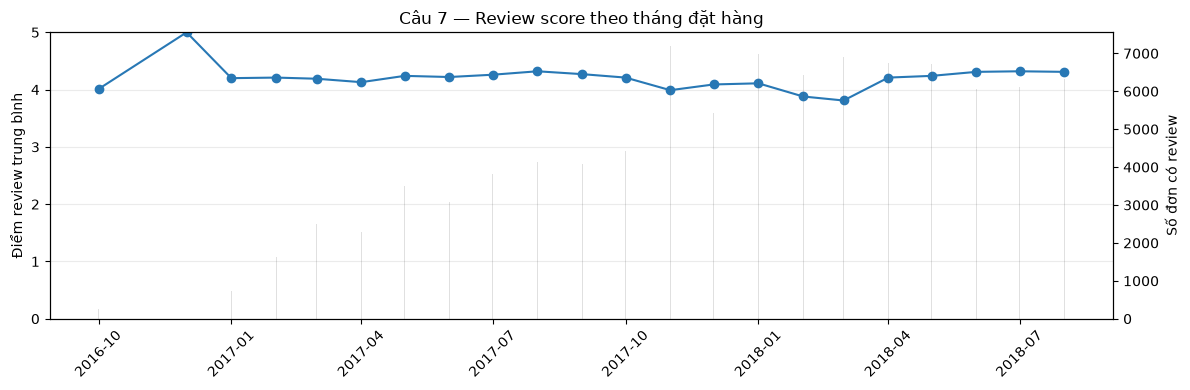

In [11]:
q09 = review_orders.groupby("purchase_year_month").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
).sort_index()
q09[["positive_pct", "low_score_pct"]] *= 100
q09 = q09.round(2)
display(q09)

fig, ax_score = plt.subplots(figsize=(12, 4))
ax_score.plot(q09.index, q09["avg_review_score"], color="#2878B5", marker="o", label="Điểm review TB")
ax_score.set_ylabel("Điểm review trung bình")
ax_score.set_ylim(0, 5)
ax_score.tick_params(axis="x", rotation=45)
ax_count = ax_score.twinx()
ax_count.bar(q09.index, q09["order_count"], alpha=0.18, color="#555555", label="Số đơn")
ax_count.set_ylabel("Số đơn có review")
ax_score.set_title("Câu 7 — Review score theo tháng đặt hàng")
ax_score.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure("07_monthly_review_score.png")
plt.show()


**Nhận xét:** Điểm theo tháng dao động, không tăng đều: đạt **4,32** vào 08/2017, giảm xuống **3,81** vào 03/2018 (tỷ lệ review thấp **21,09%**) rồi phục hồi lên **4,21** vào 04/2018. Tháng 12/2016 chỉ có **1 đơn**, nên điểm 5,00 ở tháng đó không có ý nghĩa đại diện. Các mốc dùng tháng đặt hàng; không thể diễn giải biến động theo thời gian thành nguyên nhân nếu chưa kiểm soát mùa vụ và thay đổi cơ cấu đơn.

## Câu 8 — Mức hài lòng theo bang khách hàng

So sánh số đơn, điểm trung bình, tỷ lệ review tích cực/thấp, tỷ lệ giao trễ và thời gian giao theo `customer_state`. Bảng giữ nguyên các bang như SQL; biểu đồ cho phép quan sát liệu bang có tỷ lệ giao trễ cao hơn cũng có điểm trung bình thấp hơn. Lưu ý cỡ mẫu khi so sánh bang nhỏ.


,order_count,avg_review_score,positive_pct,low_score_pct,late_rate_pct,avg_delivery_days
customer_state,,,,,,
MA,706,3.82,69.97,20.11,17.28,21.43
AL,393,3.85,71.76,21.12,20.61,24.41
RR,41,3.90,68.29,14.63,12.20,29.39
SE,332,3.90,72.29,18.98,15.06,21.45
PA,924,3.92,72.40,17.86,10.82,23.63
BA,3213,3.93,72.92,16.99,11.89,19.24
CE,1272,3.94,72.80,17.14,13.68,21.22
RJ,12136,3.97,73.48,18.27,11.95,15.24
PI,470,3.99,75.11,16.17,13.62,19.48


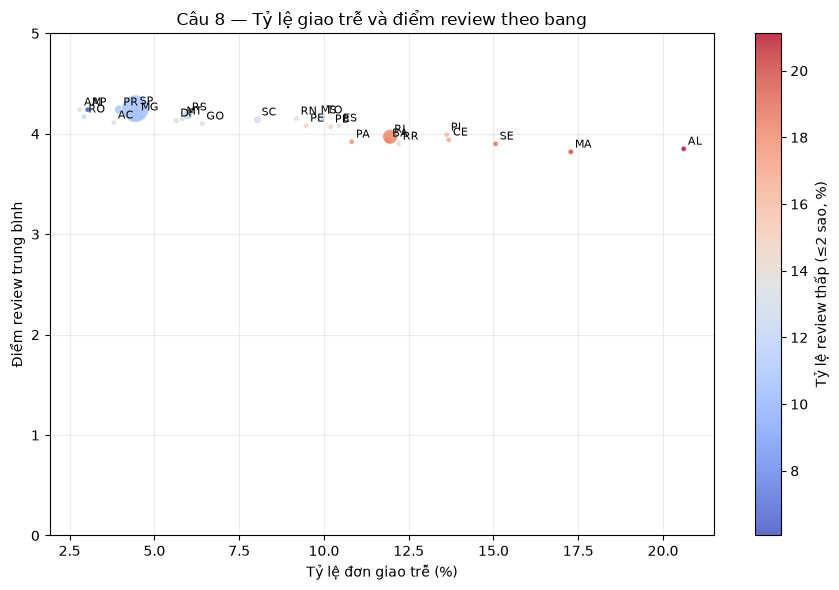

Tỷ lệ khách mua lại: 3.00% (2,801/93,349 khách)
Chi tiêu TB: khách 1 lần = 160.76 BRL | khách quay lại = 308.59 BRL


,số khách
n_orders,
1,90548
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


In [9]:
freq = orders.groupby('customer_unique_id').agg(n_orders=('order_id', 'count'), spend=('payment_total', 'sum'))
repeat = freq['n_orders'] > 1
print(f'Tỷ lệ khách mua lại: {repeat.mean() * 100:.2f}% ({repeat.sum():,}/{len(freq):,} khách)')
print(f"Chi tiêu TB: khách 1 lần = {freq.loc[~repeat, 'spend'].mean():,.2f} BRL | khách quay lại = {freq.loc[repeat, 'spend'].mean():,.2f} BRL")
freq['n_orders'].value_counts().sort_index().rename('số khách').to_frame()

## 9. Kết luận & đề xuất
| **Chủ đề** | **Phát hiện chính** | **Đề xuất** |
|---|---|---|
| Tăng trưởng | Doanh thu tháng 1–8/2018 tăng **~141%** so với cùng kỳ 2017; đỉnh tháng **11/2017** (Black Friday) | Chuẩn bị kho & vận chuyển trước mùa khuyến mãi cuối năm |
| Thời điểm mua | Thứ Hai nhiều đơn nhất, Thứ Bảy ít nhất; cao điểm **16h** | Chạy quảng cáo / flash sale đầu tuần, khung chiều |
| Danh mục | **18/74** danh mục tạo 80% doanh thu; dẫn đầu `health_beauty`, `watches_gifts`, `bed_bath_table` | Ưu tiên tồn kho và người bán ở nhóm danh mục chủ lực |
| Địa lý | SP, RJ, MG chiếm **~67%** số đơn; SP giao ~9 ngày, RR/AP > 27 ngày | Mở rộng người bán / kho vệ tinh ngoài khu Đông Nam |
| Giao hàng | Đơn cùng bang giao ~8 ngày so với ~15 ngày khác bang | Gợi ý người bán gần khách khi hiển thị sản phẩm |
| Hài lòng | Đơn trễ: điểm TB **2.27** vs **4.29**; **61%** đơn trễ bị ≤ 2 sao (vs 9%). Cả 3 kiểm định đều p < 0.05 | Giao đúng hạn là đòn bẩy lớn nhất cho review; nên ước lượng ngày giao sát thực tế |
| Thanh toán | Thẻ tín dụng **~75%** đơn, ~68% trong số đó trả góp | Duy trì trả góp không lãi cho đơn giá trị cao |
| Trung thành | Chỉ **~3%** khách mua lại | Chương trình khách hàng thân thiết, voucher cho lần mua thứ 2 |